## kNN results evaluation
Plots for the kNN experiments saved in `../output/` (5-fold stratified CV for k, then one hold-out test score per tier at the best k). Churn (`Churn Value = 1`) is the positive class. Plots are also saved to `evaluation/plots/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

OUT = Path("../output")
PLOTS = Path("plots")
PLOTS.mkdir(exist_ok=True)

# one colour per tier (fixed order) + a marker per tier so colour is not the only cue
TIERS = ["Tier 1", "Tier 2", "Tier 3"]
COLORS = {"Tier 1": "#2a78d6", "Tier 2": "#eb6834", "Tier 3": "#1baf7a"}
MARKERS = {"Tier 1": "o", "Tier 2": "s", "Tier 3": "^"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.labelsize": 10,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

folds = pd.read_csv(OUT / "fold_results.csv")
sweep = pd.read_csv(OUT / "k_sweep_summary.csv")
best = pd.read_csv(OUT / "best_k.csv").set_index("tier")
test = pd.read_csv(OUT / "test_results.csv").set_index("tier")
preds = pd.read_csv(OUT / "test_predictions.csv")


def save(name):
    plt.savefig(PLOTS / name, dpi=150, bbox_inches="tight")

### Best k and test results per tier

In [2]:
display(best[["n_features", "best_k", "cv_mean_f_measure", "k_max_tested"]].round(3))
display(test[["k", "tp", "fp", "fn", "tn", "precision", "recall", "f_measure", "roc_auc", "pr_auc"]].round(3))

,n_features,best_k,cv_mean_f_measure,k_max_tested
tier,,,,
Tier 1,4,15,0.509,20
Tier 2,6,13,0.563,20
Tier 3,19,19,0.605,20


,k,tp,fp,fn,tn,precision,recall,f_measure,roc_auc,pr_auc
tier,,,,,,,,,,
Tier 1,15,162,128,212,907,0.559,0.433,0.488,0.782,0.519
Tier 2,13,204,125,170,910,0.620,0.545,0.580,0.815,0.591
Tier 3,19,233,141,141,894,0.623,0.623,0.623,0.839,0.630


### Mean CV metric vs k
Line = mean across the 5 folds, band = ±1 std. The ring marks the best k (highest mean F-measure) of each tier.

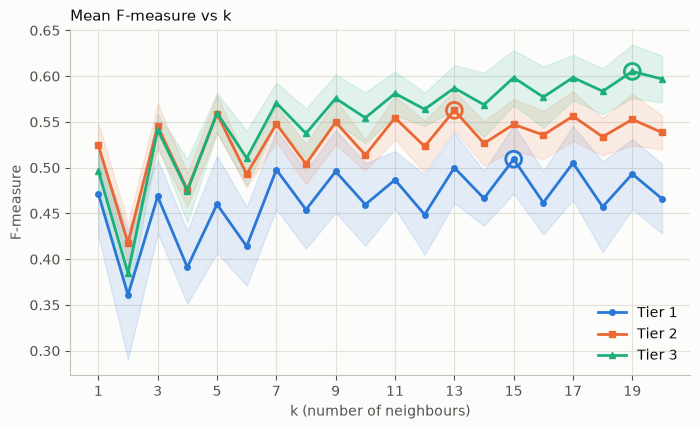

In [3]:
def plot_vs_k(ax, metric, title):
    for tier in TIERS:
        s = sweep[sweep["tier"] == tier]
        ax.plot(s["k"], s[f"{metric}_mean"], color=COLORS[tier], marker=MARKERS[tier],
                markersize=4, linewidth=2, label=tier)
        ax.fill_between(s["k"], s[f"{metric}_mean"] - s[f"{metric}_std"],
                        s[f"{metric}_mean"] + s[f"{metric}_std"], color=COLORS[tier], alpha=0.12)
        bk = best.loc[tier, "best_k"]
        ax.scatter([bk], [s.loc[s["k"] == bk, f"{metric}_mean"].iloc[0]], s=130,
                   facecolors="none", edgecolors=COLORS[tier], linewidths=2, zorder=5)
    ax.set_xlabel("k (number of neighbours)")
    ax.set_title(title, loc="left")
    ax.set_xticks(sorted(sweep["k"].unique())[::2])


fig, ax = plt.subplots(figsize=(8, 4.5))
plot_vs_k(ax, "f_measure", "Mean F-measure vs k")
ax.set_ylabel("F-measure")
ax.legend()
save("f_measure_vs_k.png")
plt.show()

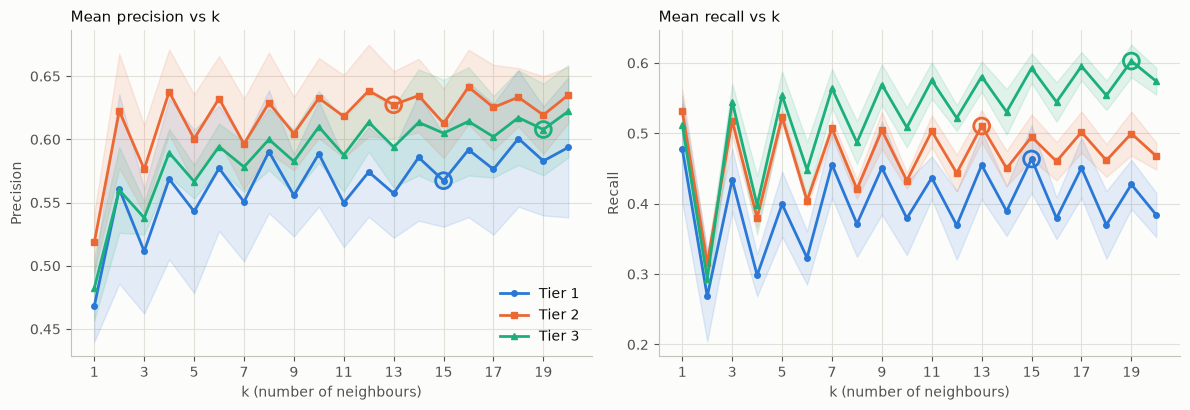

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_vs_k(axes[0], "precision", "Mean precision vs k")
plot_vs_k(axes[1], "recall", "Mean recall vs k")
axes[0].set_ylabel("Precision")
axes[1].set_ylabel("Recall")
axes[0].legend()
plt.tight_layout()
save("precision_recall_vs_k.png")
plt.show()

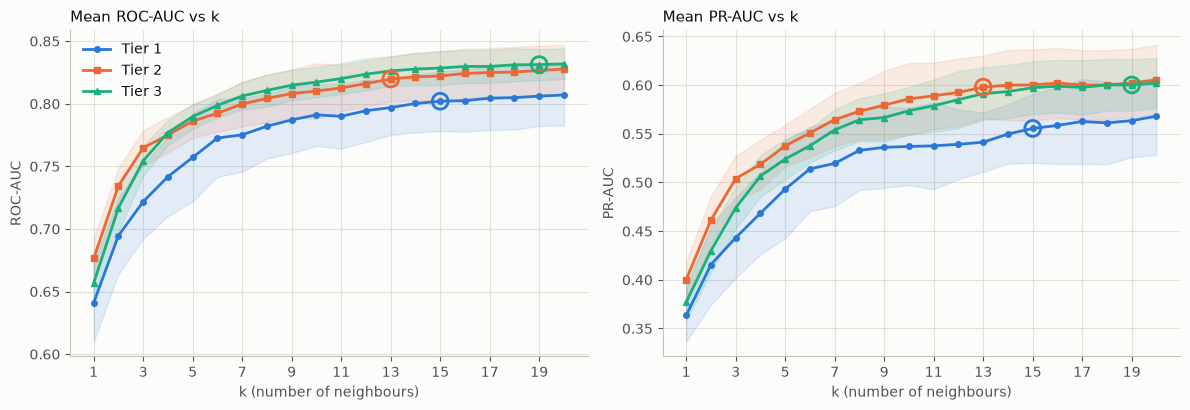

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_vs_k(axes[0], "roc_auc", "Mean ROC-AUC vs k")
plot_vs_k(axes[1], "pr_auc", "Mean PR-AUC vs k")
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("PR-AUC")
axes[0].legend()
plt.tight_layout()
save("auc_vs_k.png")
plt.show()

### Per-fold results at the best k
Each dot is one fold; boxes show the spread across the 5 folds.

/var/folders/cc/mynr0f9s0112l_zbr19cp6z00000gn/T/ipykernel_55639/2179514125.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#0b0b0b'` for the same effect.

  sns.stripplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, dodge=True,


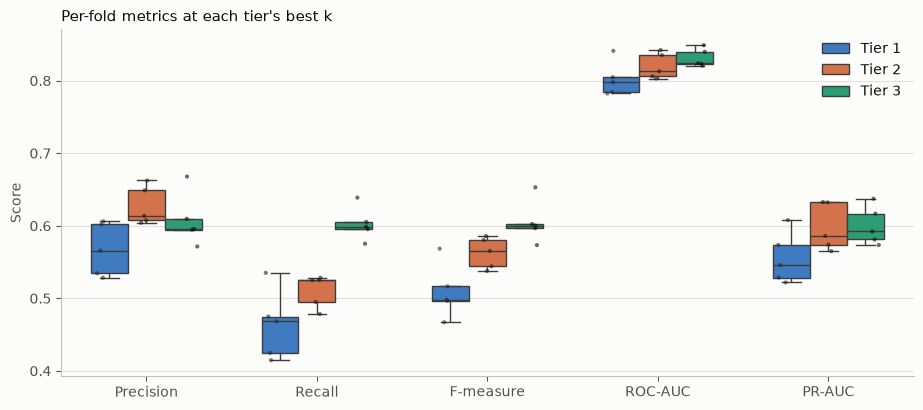

,tier,k,fold,tp,fp,fn,tn,precision,recall,f_measure,roc_auc,pr_auc
0,Tier 1,15,1,140,125,159,703,0.528,0.468,0.496,0.784,0.546
1,Tier 1,15,2,160,104,139,724,0.606,0.535,0.568,0.841,0.608
2,Tier 1,15,3,124,108,175,720,0.534,0.415,0.467,0.782,0.529
3,Tier 1,15,4,142,109,157,719,0.566,0.475,0.516,0.798,0.522
4,Tier 1,15,5,127,84,172,743,0.602,0.425,0.498,0.805,0.574
5,Tier 2,13,1,158,102,141,726,0.608,0.528,0.565,0.806,0.574
6,Tier 2,13,2,157,85,142,743,0.649,0.525,0.580,0.842,0.633
7,Tier 2,13,3,148,97,151,731,0.604,0.495,0.544,0.803,0.586
8,Tier 2,13,4,143,90,156,738,0.614,0.478,0.538,0.813,0.565
9,Tier 2,13,5,157,80,142,747,0.662,0.525,0.586,0.835,0.632


In [6]:
rows = [folds[(folds["tier"] == t) & (folds["k"] == best.loc[t, "best_k"])] for t in TIERS]
at_best = pd.concat(rows)
long = at_best.melt(id_vars=["tier", "fold"],
                    value_vars=["precision", "recall", "f_measure", "roc_auc", "pr_auc"],
                    var_name="metric", value_name="value")
long["metric"] = long["metric"].map({"precision": "Precision", "recall": "Recall",
                                     "f_measure": "F-measure", "roc_auc": "ROC-AUC",
                                     "pr_auc": "PR-AUC"})

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, palette=COLORS,
            width=0.65, linewidth=1, fliersize=0, ax=ax)
sns.stripplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, dodge=True,
              color="#0b0b0b", size=3, alpha=0.6, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_title("Per-fold metrics at each tier's best k", loc="left")
ax.legend(title="")
save("per_fold_metrics.png")
plt.show()

display(at_best[["tier", "k", "fold", "tp", "fp", "fn", "tn", "precision", "recall",
                 "f_measure", "roc_auc", "pr_auc"]].round(3).reset_index(drop=True))

### Confusion matrices (hold-out test set, best k)
Layout follows the course `[[TP, FP], [FN, TN]]`: rows are the predicted class, columns the actual class. Each cell shows the count and its share of all test customers.

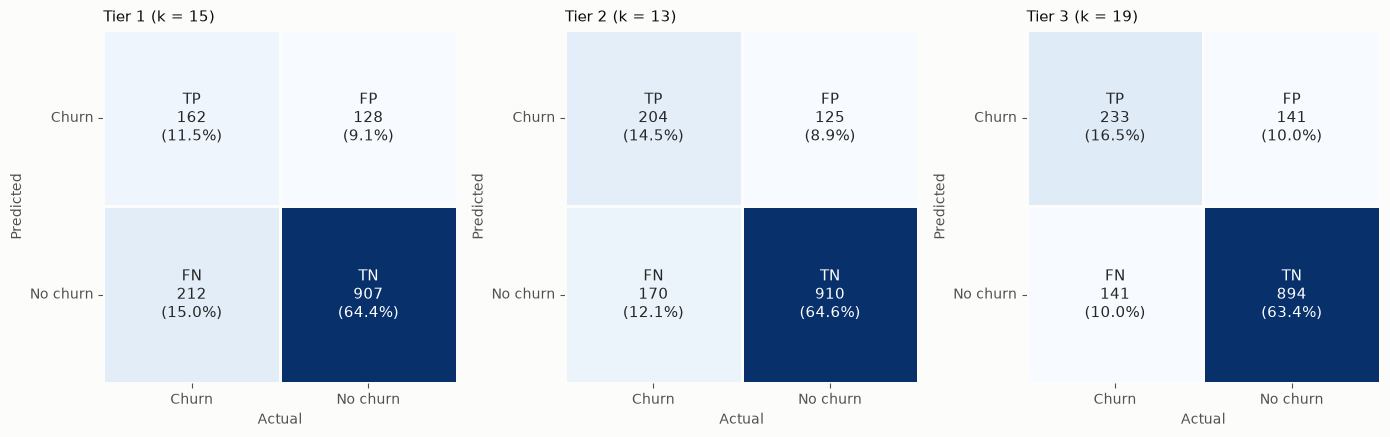

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, tier in zip(axes, TIERS):
    t = test.loc[tier]
    cm = np.array([[t["tp"], t["fp"]], [t["fn"], t["tn"]]]).astype(int)
    names = np.array([["TP", "FP"], ["FN", "TN"]])
    annot = np.array([[f"{names[i, j]}\n{cm[i, j]}\n({cm[i, j] / cm.sum():.1%})"
                       for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, linewidths=2,
                linecolor="#fcfcfb", square=True, ax=ax, annot_kws={"fontsize": 11})
    ax.set_xticklabels(["Churn", "No churn"])
    ax.set_yticklabels(["Churn", "No churn"], rotation=0)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{tier} (k = {int(t['k'])})", loc="left")
    ax.grid(False)
plt.tight_layout()
save("confusion_matrices.png")
plt.show()

### ROC and precision-recall curves (hold-out test set)

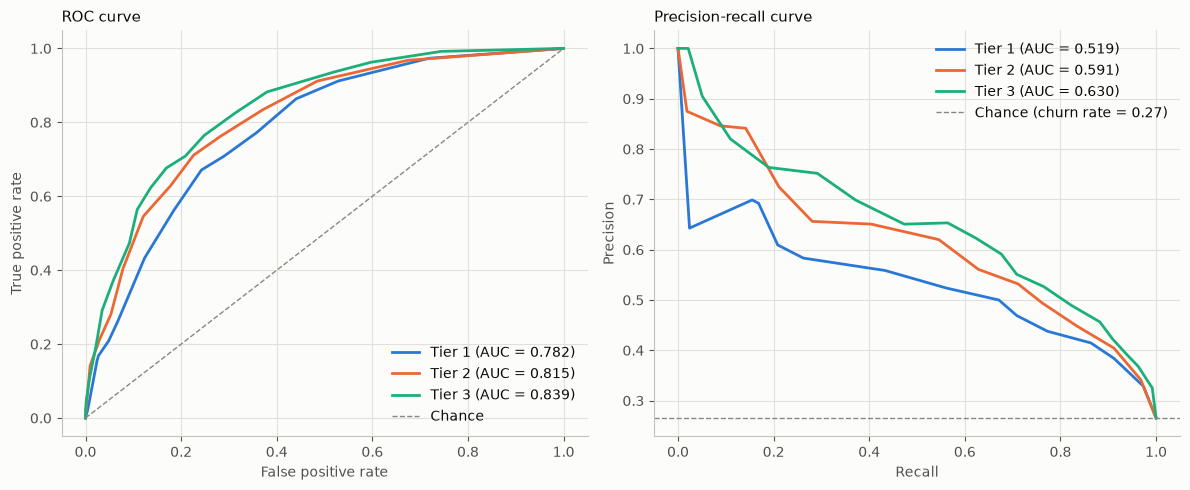

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for tier in TIERS:
    p = preds[preds["tier"] == tier]
    fpr, tpr, _ = roc_curve(p["y_true"], p["y_score"])
    prec, rec, _ = precision_recall_curve(p["y_true"], p["y_score"])
    axes[0].plot(fpr, tpr, color=COLORS[tier], linewidth=2,
                 label=f"{tier} (AUC = {test.loc[tier, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=COLORS[tier], linewidth=2,
                 label=f"{tier} (AUC = {test.loc[tier, 'pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1, label="Chance")
base = preds["y_true"].mean()
axes[1].axhline(base, color="#898781", linestyle="--", linewidth=1,
                label=f"Chance (churn rate = {base:.2f})")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(xlabel="Recall", ylabel="Precision")
axes[0].set_title("ROC curve", loc="left")
axes[1].set_title("Precision-recall curve", loc="left")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout()
save("roc_pr_curves.png")
plt.show()

### Tier comparison on the test set

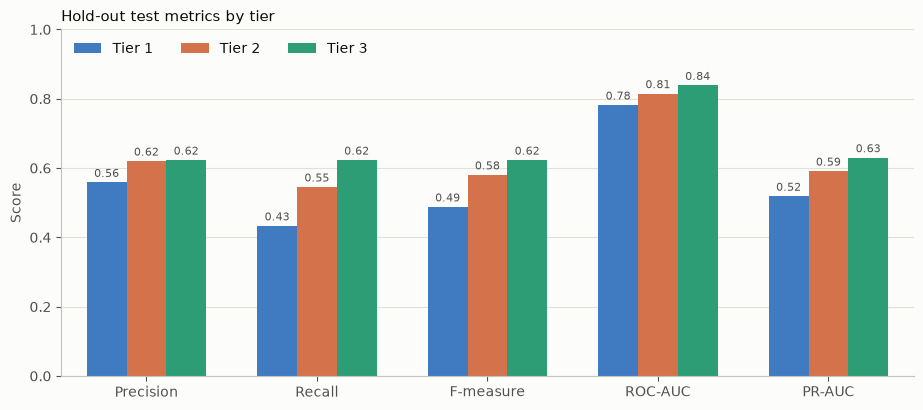

In [9]:
metrics = {"precision": "Precision", "recall": "Recall", "f_measure": "F-measure",
           "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}
comp = test.reset_index().melt(id_vars="tier", value_vars=list(metrics),
                               var_name="metric", value_name="value")
comp["metric"] = comp["metric"].map(metrics)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=comp, x="metric", y="value", hue="tier", hue_order=TIERS, palette=COLORS,
            width=0.7, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2, color="#52514e")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Hold-out test metrics by tier", loc="left")
ax.legend(title="", loc="upper left", ncol=3)
save("tier_comparison.png")
plt.show()